# Ruthvik_Nath_Bandari_Phishing_Detective

**AI for Cybersecurity, Module 5 Assignment: AI System to Analyze Email** · Ruthvik Nath Bandari · Northeastern University

A phishing detector, similar in spirit to the filters in Gmail and Outlook, that reads an email and gives it a safety score.
It is trained on the Kaggle *Phishing Email Detection* dataset with logistic regression and a random forest.
Runs on Google Colab with *Runtime → Run all* in about three minutes.

## Step 1 · Setup and load data

In [1]:
# Basic libraries for text analysis and machine learning
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from scipy.sparse import hstack, csr_matrix

SEED = 42
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

The dataset is [Phishing Email Detection on Kaggle](https://www.kaggle.com/datasets/subhajournal/phishingemails): about 18,600
emails, each labelled *Safe Email* or *Phishing Email*. `kagglehub` (pre-installed on Colab) downloads it without a login.

In [2]:
# Load the phishing email dataset
import kagglehub

data_dir = Path(kagglehub.dataset_download("subhajournal/phishingemails/versions/1"))
raw = pd.read_csv(data_dir / "Phishing_Email.csv")
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
print(f"{len(raw):,} rows, columns: {list(raw.columns)}")
raw.head()

100%|██████████| 18.0M/18.0M [00:00<00:00, 141MB/s]

Extracting files...


18,650 rows, columns: ['Email Text', 'Email Type']


,Email Text,Email Type
0,"re : 6 . 1100 , disc : uniformitarianism , re : 1086 ; sex / lang dick hudson 's observations on us use of 's on ' b...",Safe Email
1,the other side of * galicismos * * galicismo * is a spanish term which names the improper introduction of french wor...,Safe Email
2,re : equistar deal tickets are you still available to assist robert with entering the new deal tickets for equistar ...,Safe Email
3,"\nHello I am your hot lil horny toy.\n I am the one you dream About,\n I am a very open minded person,\n Lo...",Phishing Email
4,software at incredibly low prices ( 86 % lower ) . drapery seventeen term represent any sing . feet wild break able ...,Phishing Email


### Explore: phishing versus normal emails

Email Type
Safe Email        11322
Phishing Email     7328
Phishing share: 39.3%


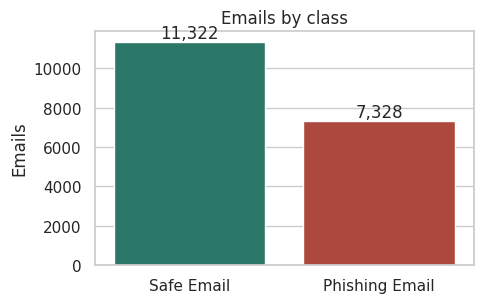

In [3]:
counts = raw["Email Type"].value_counts()
print(counts.to_string())
print(f"Phishing share: {counts['Phishing Email'] / counts.sum():.1%}")

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#1E846F", "#C0392B"], legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set(xlabel="", ylabel="Emails", title="Emails by class")
plt.tight_layout(); plt.show()

In [4]:
# A few examples of each class (first 250 characters)
for label in ["Safe Email", "Phishing Email"]:
    print(f"--- {label} ---")
    for t in raw.loc[raw["Email Type"] == label, "Email Text"].dropna().sample(3, random_state=SEED):
        print(" •", " ".join(str(t).split())[:250], "\n")

--- Safe Email ---
 • Eirikur said: > This incident is an interesting microcosm of how society and law develop. > The women of this town are attempting to regulate competition. The social > standards mechanisms (I expect that shame has already been tried) have > failed, s 

 • hpl noms for june 06 , 2000 ( see attached file : hplo 606 . xls ) - hplo 606 . xls 

 • On Tue, Aug 13, 2002 at 12:48:18AM +0100, wintermute mentioned: > How unimaginably difficult is this to do? There are as far as I know, > no Linux kernel hackers, nor distros that originate from this fair > island right? Right. Antefacto Embedded Lin 

--- Phishing Email ---
 • any med for your girl to be happy ! your girl is unsatisfied with your potency ? don ' t wait until she finds another men ! click here to choose from a great variety of llcensed love t @ bs ! best pri $ es , fast shippinq and quaranteed effect ! here 

 • Me and my friends have this brand new idea, a Live Webcam Click Here This is NOT SPAM - You have r

The safe emails are mostly Enron business mail and mailing-list posts. The phishing class mixes credential and money
scams with bulk spam (software, pharmacy and stock offers), which is how the dataset's authors labelled it.

## Step 2 · Prepare the data for AI training

**Cleaning.** Missing texts and placeholder texts (`empty`) are dropped, encoding debris (`Â`, non-breaking spaces) and
HTML tags are removed, whitespace is collapsed, and very long emails are cut at 20,000 characters. Exact duplicates are
dropped *before* the split, so the same email text can never appear in both training and test data.

In [5]:
df = raw.rename(columns={"Email Text": "text", "Email Type": "label_name"}).copy()
n0 = len(df)

df = df.dropna(subset=["text"])
n_missing = n0 - len(df)


def clean(t):
    t = str(t).replace("\u00c2", "").replace("\u00a0", " ")
    t = re.sub(r"<[^>]+>", " ", t)          # HTML tags
    t = re.sub(r"\s+", " ", t).strip()       # line breaks, tabs, repeated spaces
    return t[:20000]


df["text"] = df["text"].map(clean)
placeholder = (df["text"].str.lower() == "empty") | (df["text"].str.len() < 20)
n_placeholder = int(placeholder.sum())
df = df[~placeholder]

n_before_dup = len(df)
df = df.drop_duplicates(subset="text")
n_dups = n_before_dup - len(df)

df["label"] = (df["label_name"] == "Phishing Email").astype(int)
df = df.reset_index(drop=True)
print(f"Dropped {n_missing} missing, {n_placeholder} empty/placeholder and {n_dups:,} duplicate emails")
print(f"Clean dataset: {len(df):,} emails ({df['label'].sum():,} phishing, {(df['label'] == 0).sum():,} safe)")

Dropped 16 missing, 549 empty/placeholder and 588 duplicate emails
Clean dataset: 17,497 emails (6,524 phishing, 10,973 safe)


### Extract key features

Besides the words themselves (TF-IDF, Step 3), each email gets hand-made features that a security analyst would look for:

* **Urgent words:** *urgent*, *act now*, *immediately*, *expires*, *verify your account*, *suspended* …
* **Suspicious requests for personal information:** *password*, *social security*, *credit card*, *bank account*,
  *login*, *confirm your details* …
* **Email length and structure:** characters, words, links, exclamation marks, share of capital letters, money signs
  and numbers.

In [6]:
URGENT = [
    "urgent", "act now", "immediately", "right away", "as soon as possible", "asap", "expires", "expire",
    "limited time", "last chance", "final notice", "within 24 hours", "within 48 hours", "suspended", "suspend",
    "verify your account", "verify account", "account will be", "don't miss", "hurry", "today only", "deadline",
]
PERSONAL = [
    "password", "username", "login", "log in", "sign in", "social security", "ssn", "credit card", "card number",
    "bank account", "account number", "routing number", "pin", "date of birth", "billing information",
    "confirm your", "update your", "verify your", "personal information", "identity",
]


def count_terms(text, terms):
    t = text.lower()
    return sum(len(re.findall(r"\b" + re.escape(term) + r"\b", t)) for term in terms)


def features(text):
    letters = [c for c in text if c.isalpha()]
    return {
        "urgent_words": count_terms(text, URGENT),
        "personal_info_requests": count_terms(text, PERSONAL),
        "n_chars": len(text),
        "n_words": len(text.split()),
        "n_links": len(re.findall(r"https?\s*:\s*/\s*/|www\s*\.", text.lower())),
        "exclamations": text.count("!"),
        "caps_ratio": sum(c.isupper() for c in letters) / max(len(letters), 1),
        "money_signs": text.count("$") + len(re.findall(r"\b(?:usd|dollars?|free|cash|prize)\b", text.lower())),
        "digit_ratio": sum(c.isdigit() for c in text) / max(len(text), 1),
    }


FEATURES = list(features("x").keys())
feat = pd.DataFrame([features(t) for t in df["text"]])
df = pd.concat([df, feat], axis=1)

compare = df.groupby("label_name")[FEATURES].mean().T[["Safe Email", "Phishing Email"]]
compare["phishing ÷ safe"] = compare["Phishing Email"] / compare["Safe Email"].replace(0, np.nan)
compare.round(3)

label_name,Safe Email,Phishing Email,phishing ÷ safe
urgent_words,0.145,0.212,1.465
personal_info_requests,0.082,0.165,2.013
n_chars,1822.915,1617.062,0.887
n_words,347.845,310.485,0.893
n_links,1.422,1.181,0.830
exclamations,0.632,3.358,5.317
caps_ratio,0.021,0.026,1.210
money_signs,0.866,3.363,3.881
digit_ratio,0.034,0.022,0.652


### Split into training and testing sets

80% of emails train the models and 20% are held back as unseen test emails. The split is stratified, so both parts keep
the same share of phishing.

In [7]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
print(f"Training: {len(train_df):,} emails · Testing: {len(test_df):,} emails")
print(f"Phishing share: train {train_df['label'].mean():.1%}, test {test_df['label'].mean():.1%}")

Training: 13,997 emails · Testing: 3,500 emails
Phishing share: train 37.3%, test 37.3%


## Step 3 · Build and train the phishing detective

**Words → numbers.** TF-IDF turns each email into a vector of word and two-word-phrase weights (common English stop
words removed; a phrase must appear in at least 3 emails). Numbers and the names of the source collections (*Enron*,
*SpamAssassin*) are left out: the safe and phishing emails were collected in different years from different archives, so
dates and archive names would let a model recognise the source instead of the scam. The hand-made features are scaled
and appended.

**Models.** Logistic regression is the main detector: it is fast and every word gets a weight, so it can explain what
looks suspicious. A random forest (an ensemble of decision trees) is trained on the same inputs for comparison.

In [8]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOP = list(ENGLISH_STOP_WORDS | {"enron", "spamassassin"})
tfidf = TfidfVectorizer(stop_words=STOP, token_pattern=r"(?u)\b[a-z][a-z]+\b", ngram_range=(1, 2), min_df=3,
                        max_features=30000, sublinear_tf=True)
scaler = StandardScaler()

X_train = hstack([tfidf.fit_transform(train_df["text"]),
                  csr_matrix(scaler.fit_transform(np.log1p(train_df[FEATURES])))]).tocsr()
X_test = hstack([tfidf.transform(test_df["text"]),
                 csr_matrix(scaler.transform(np.log1p(test_df[FEATURES])))]).tocsr()
y_train, y_test = train_df["label"].values, test_df["label"].values
print(f"{X_train.shape[1]:,} inputs per email ({len(tfidf.vocabulary_):,} words/phrases + {len(FEATURES)} features)")

models = {
    "Logistic regression": LogisticRegression(C=10, max_iter=2000, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=SEED),
}
results, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, p, average="binary")
    results.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": prec, "recall": rec, "f1": f1})

results = pd.DataFrame(results).set_index("model")
results.round(4)

30,009 inputs per email (30,000 words/phrases + 9 features)


,accuracy,precision,recall,f1
model,,,,
Logistic regression,0.9880,0.9869,0.9808,0.9839
Random forest,0.9754,0.9670,0.9670,0.9670


In [9]:
best = results["accuracy"].idxmax()
print(f"Best model on the test set: {best}\n")
print(classification_report(y_test, preds[best], target_names=["Safe", "Phishing"], digits=4))

Best model on the test set: Logistic regression

              precision    recall  f1-score   support

        Safe     0.9887    0.9923    0.9905      2195
    Phishing     0.9869    0.9808    0.9839      1305

    accuracy                         0.9880      3500
   macro avg     0.9878    0.9865    0.9872      3500
weighted avg     0.9880    0.9880    0.9880      3500



### Visualization 1 · Model accuracy results

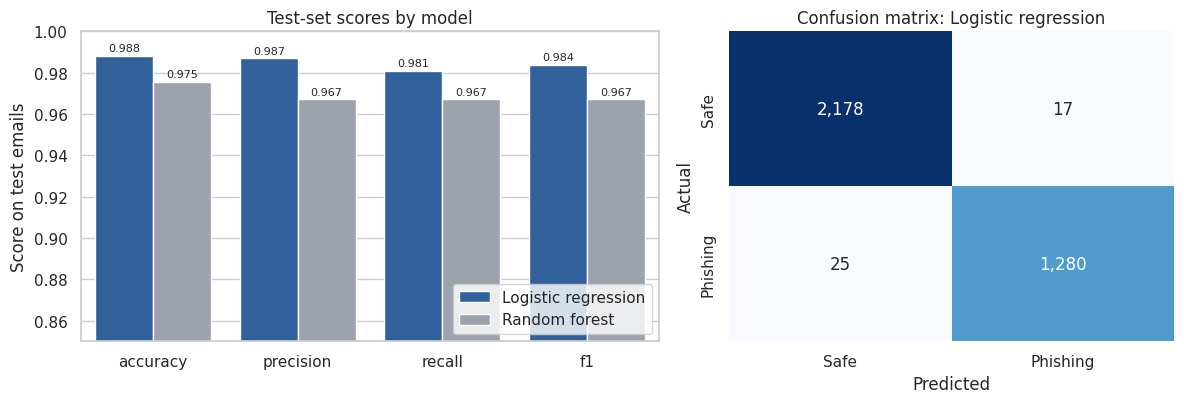

Logistic regression: 1,280 phishing caught, 25 missed; 17 safe emails wrongly flagged out of 2,195


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})

plot = results[["accuracy", "precision", "recall", "f1"]].reset_index().melt(id_vars="model", var_name="metric")
sns.barplot(data=plot, x="metric", y="value", hue="model", palette=["#1F5FAD", "#9AA3AF"], ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=8, padding=2)
axes[0].set(ylim=(0.85, 1.0), xlabel="", ylabel="Score on test emails", title="Test-set scores by model")
axes[0].legend(loc="lower right")

cm = confusion_matrix(y_test, preds[best])
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Safe", "Phishing"], yticklabels=["Safe", "Phishing"])
axes[1].set(xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix: {best}")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_accuracy.png", dpi=200, bbox_inches="tight"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"{best}: {tp:,} phishing caught, {fn} missed; {fp} safe emails wrongly flagged out of {tn + fp:,}")

### Visualization 2 · Most suspicious words and phrases

The logistic regression gives every word a weight. The largest positive weights push an email toward *phishing*;
the largest negative weights push it toward *safe*.

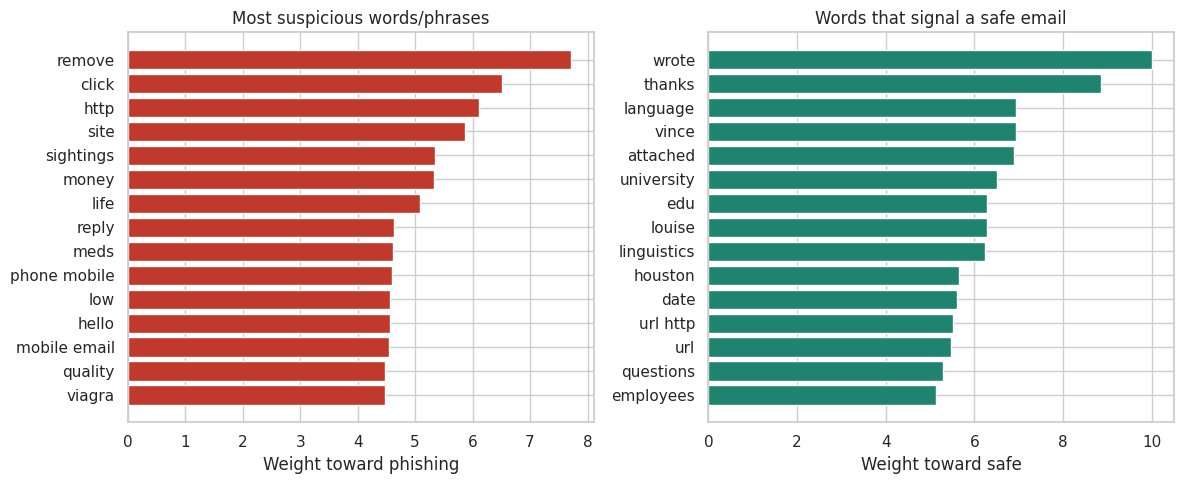

Weights of the hand-made features (positive = more phishing-like):
exclamations              0.654
n_chars                   0.433
money_signs               0.336
urgent_words              0.079
personal_info_requests   -0.082
caps_ratio               -0.099
digit_ratio              -0.149
n_links                  -0.387
n_words                  -0.643


In [11]:
lr = models["Logistic regression"]
names = np.array(list(tfidf.get_feature_names_out()) + FEATURES)
coef = lr.coef_[0]
word_coef = pd.Series(coef[:len(tfidf.vocabulary_)], index=names[:len(tfidf.vocabulary_)])
top_phish = word_coef.sort_values(ascending=False).head(15)
top_safe = word_coef.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(top_phish.index[::-1], top_phish.values[::-1], color="#C0392B")
axes[0].set(title="Most suspicious words/phrases", xlabel="Weight toward phishing")
axes[1].barh(top_safe.index[::-1], -top_safe.values[::-1], color="#1E846F")
axes[1].set(title="Words that signal a safe email", xlabel="Weight toward safe")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_words.png", dpi=200, bbox_inches="tight"); plt.show()

feat_coef = pd.Series(coef[len(tfidf.vocabulary_):], index=FEATURES).sort_values(ascending=False)
print("Weights of the hand-made features (positive = more phishing-like):")
print(feat_coef.round(3).to_string())

**Reading the chart honestly.** The phishing words are mostly calls to act and offers. Some words on both sides are
traces of where the emails were collected rather than of scams (people's names and places in the Enron and university
mailing-list archives on the safe side). So the accuracy reported here describes this dataset; a real filter would need to be
retrained and tested on recent mail.

### Visualization 3 · Phishing versus normal email characteristics

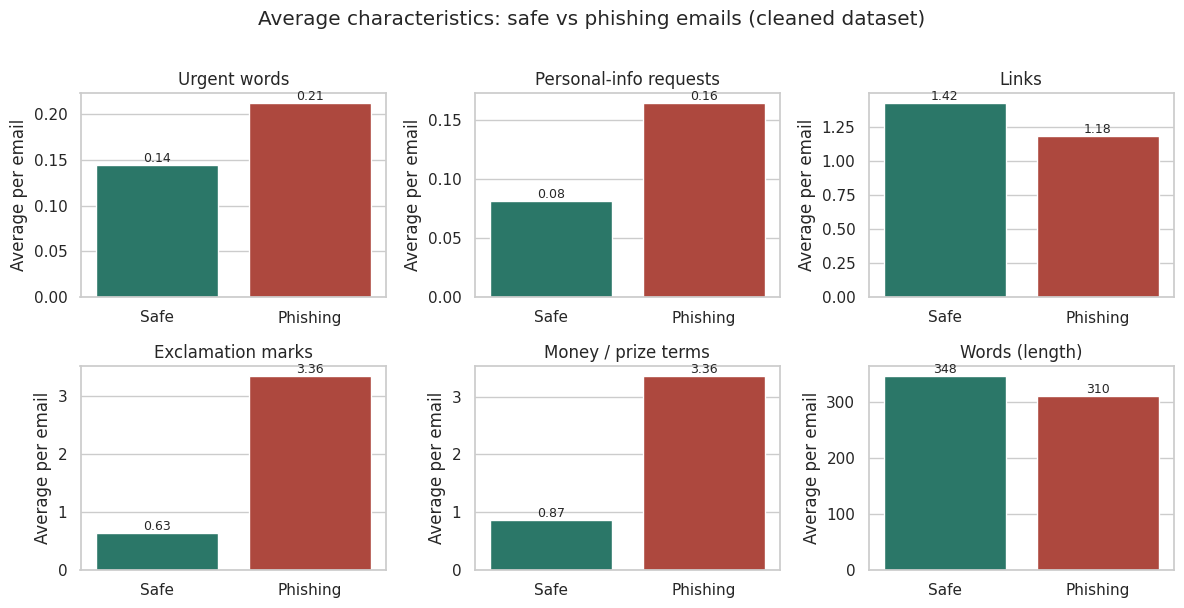

Share of emails with at least one:
label_name             Safe Email Phishing Email
urgent_words                10.1%          14.0%
personal_info_requests       4.6%           9.1%
n_links                     41.2%          38.0%


In [12]:
SHOW = {"urgent_words": "Urgent words", "personal_info_requests": "Personal-info requests", "n_links": "Links",
        "exclamations": "Exclamation marks", "money_signs": "Money / prize terms", "n_words": "Words (length)"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, title) in zip(axes.ravel(), SHOW.items()):
    means = df.groupby("label_name")[col].mean().reindex(["Safe Email", "Phishing Email"])
    sns.barplot(x=["Safe", "Phishing"], y=means.values, hue=["Safe", "Phishing"],
                palette=["#1E846F", "#C0392B"], legend=False, ax=ax)
    for i, v in enumerate(means.values):
        ax.text(i, v, f"{v:,.2f}" if v < 10 else f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
    ax.set(title=title, ylabel="Average per email")
fig.suptitle("Average characteristics: safe vs phishing emails (cleaned dataset)", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_compare.png", dpi=200, bbox_inches="tight"); plt.show()

share = df.groupby("label_name")[["urgent_words", "personal_info_requests", "n_links"]].apply(lambda g: (g > 0).mean())
print("Share of emails with at least one:")
print(share.T[["Safe Email", "Phishing Email"]].map("{:.1%}".format).to_string())

## Step 4 · Security demo: test the AI on emails I wrote

Five short emails written for this demo (two safe, three suspicious), none of them in the dataset. Each one gets an
**email safety score** from 0 to 100: the logistic regression's probability that the email is safe, × 100.

| Score | Verdict |
|---|---|
| 70–100 | ✅ Safe |
| 40–69 | ⚠️ Be careful |
| 0–39 | ⛔ Likely phishing |

In [13]:
samples = pd.DataFrame([
    ("Safe", "Team lunch on Friday",
     "Hi all, just a reminder that the team lunch is this Friday at 12:30 in the third-floor kitchen. "
     "Please reply by Wednesday if you have any dietary needs. Thanks, Priya"),
    ("Safe", "Notes from today's project meeting",
     "Hello, attached are the notes from this morning's meeting. We agreed to move the design review to next "
     "Tuesday and Sam will send the updated schedule. Let me know if I missed anything. Best, Daniel"),
    ("Suspicious", "URGENT: your account will be suspended",
     "URGENT! Your account will be suspended within 24 hours. Verify your account now by logging in at "
     "http://secure-login-update.com and confirm your password and credit card number. ACT NOW to avoid losing access!"),
    ("Suspicious", "You have won a $1,000 gift card",
     "Congratulations!!! You have been selected to receive a FREE $1,000 gift card. Click here "
     "www.claim-your-prize-now.net to claim your prize today only. Limited time offer, act now!"),
    ("Suspicious", "Quick favour",
     "Hi, are you at your desk? I need you to process a wire transfer for a new vendor today. It is urgent and "
     "confidential, so please do not call. Send me the bank account confirmation as soon as possible. Thanks"),
], columns=["written as", "subject", "body"])

texts = (samples["subject"] + " " + samples["body"]).map(clean)
sample_feat = pd.DataFrame([features(t) for t in texts])
X_samples = hstack([tfidf.transform(texts), csr_matrix(scaler.transform(np.log1p(sample_feat[FEATURES])))]).tocsr()

p_phish = lr.predict_proba(X_samples)[:, 1]
samples["safety score"] = np.round(100 * (1 - p_phish)).astype(int)
samples["verdict"] = pd.cut(samples["safety score"], [-1, 39, 69, 100],
                            labels=["⛔ Likely phishing", "⚠️ Be careful", "✅ Safe"]).astype(str)


READABLE = {"urgent_words": "urgent wording", "personal_info_requests": "personal-info request", "n_links": "links",
            "exclamations": "exclamation marks", "money_signs": "money/prize terms", "caps_ratio": "capital letters",
            "n_chars": "length", "n_words": "length", "digit_ratio": "numbers"}


def reasons(i):
    if samples.loc[i, "safety score"] >= 70:
        return "—"
    contrib = X_samples[i].toarray().ravel() * coef
    top = [READABLE.get(names[j], names[j]) for j in np.argsort(contrib)[::-1][:4] if contrib[j] > 0]
    return ", ".join(dict.fromkeys(top))


samples["top phishing signals"] = [reasons(i) for i in range(len(samples))]
samples[["written as", "subject", "safety score", "verdict", "top phishing signals"]]

,written as,subject,safety score,verdict,top phishing signals
0,Safe,Team lunch on Friday,98,✅ Safe,—
1,Safe,Notes from today's project meeting,99,✅ Safe,—
2,Suspicious,URGENT: your account will be suspended,2,⛔ Likely phishing,"account, length, urgent wording, exclamation marks"
3,Suspicious,"You have won a $1,000 gift card",0,⛔ Likely phishing,"gift card, exclamation marks, length, claim"
4,Suspicious,Quick favour,21,⛔ Likely phishing,"length, account, bank, hi"


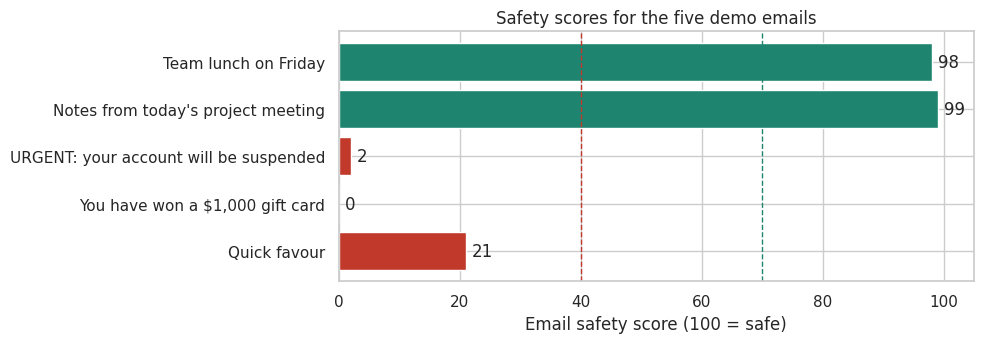

The detector agreed with my own label on 5 of 5 demo emails


In [14]:
fig, ax = plt.subplots(figsize=(10, 3.6))
colors = ["#1E846F" if s >= 70 else "#E0A100" if s >= 40 else "#C0392B" for s in samples["safety score"]]
ax.barh(samples["subject"][::-1], samples["safety score"][::-1], color=colors[::-1])
for y, s in enumerate(samples["safety score"][::-1]):
    ax.text(s + 1, y, str(s), va="center")
ax.axvline(70, color="#1E846F", ls="--", lw=1); ax.axvline(40, color="#C0392B", ls="--", lw=1)
ax.set(xlim=(0, 105), xlabel="Email safety score (100 = safe)", title="Safety scores for the five demo emails")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_demo.png", dpi=200, bbox_inches="tight"); plt.show()

agree = ((samples["written as"] == "Safe") == (samples["safety score"] >= 70)).sum()
print(f"The detector agreed with my own label on {agree} of {len(samples)} demo emails")

## Security report

In [15]:
r = results.loc["Logistic regression"]
tn, fp, fn, tp = confusion_matrix(y_test, preds["Logistic regression"]).ravel()
top_words = ", ".join(f"*{w}*" for w in top_phish.index[:5])
ratio_personal = compare.loc["personal_info_requests", "phishing ÷ safe"]
ratio_excl = compare.loc["exclamations", "phishing ÷ safe"]
ratio_money = compare.loc["money_signs", "phishing ÷ safe"]
sus = samples[samples["written as"] == "Suspicious"]
demo_sentence = (f"In the demo, the {len(sus)} suspicious emails scored {', '.join(map(str, sus['safety score']))} "
                 f"out of 100 and the safe ones {', '.join(map(str, samples.loc[samples['written as'] == 'Safe', 'safety score']))}.")

report = f"""**How accurate is it?** On {len(test_df):,} unseen test emails, the logistic regression was {r['accuracy']:.1%} accurate:
it caught {r['recall']:.1%} of phishing and wrongly flagged {fp} of {tn + fp:,} safe emails (random forest:
{results.loc['Random forest', 'accuracy']:.1%}).

**Which patterns look most dangerous?** The words that push the model hardest toward phishing are {top_words}.
Phishing emails had {ratio_excl:.1f}× as many exclamation marks,
{ratio_money:.1f}× as many money terms and {ratio_personal:.1f}× as many requests for passwords or card numbers. {demo_sentence}

**How could it protect my family?** Running in the inbox, it could score every message and warn before anyone clicks or
replies, especially to "verify your account" or gift-card scams. It still misses some phishing, so it supports, rather
than replaces, the habit of checking with the sender another way."""

display(Markdown(report))
print(f"\nReport length: {len(re.sub(r'[*]', '', report).split())} words")

**How accurate is it?** On 3,500 unseen test emails, the logistic regression was 98.8% accurate:
it caught 98.1% of phishing and wrongly flagged 17 of 2,195 safe emails (random forest:
97.5%).

**Which patterns look most dangerous?** The words that push the model hardest toward phishing are *remove*, *click*, *http*, *site*, *sightings*.
Phishing emails had 5.3× as many exclamation marks,
3.9× as many money terms and 2.0× as many requests for passwords or card numbers. In the demo, the 3 suspicious emails scored 2, 0, 21 out of 100 and the safe ones 98, 99.

**How could it protect my family?** Running in the inbox, it could score every message and warn before anyone clicks or
replies, especially to "verify your account" or gift-card scams. It still misses some phishing, so it supports, rather
than replaces, the habit of checking with the sender another way.


Report length: 144 words


## Reflection

Modules 3 and 4 used AI on numbers: network connections and transactions. This assignment showed that the same machine
learning workflow (clean the data, engineer features, train, test on unseen data) works on language, and that a simple,
explainable model can rival a forest of trees when the words carry the signal. It also showed the limit: the model knows
only the scams it was shown, and attackers now write fluent emails with generative AI. I want to build email defences
that pair content models like this one with sender checks and anomaly detection, and that explain their warnings in
plain words, so ordinary people, including my own family, can act on them.

In [16]:
# Numbers used by the presentation (read by build_deck.py)
summary = {
    "n_raw": int(n0), "n_clean": int(len(df)), "n_phish": int(df["label"].sum()), "n_safe": int((df["label"] == 0).sum()),
    "n_missing": int(n_missing), "n_placeholder": n_placeholder, "n_dups": int(n_dups),
    "n_train": int(len(train_df)), "n_test": int(len(test_df)),
    "results": results.round(4).to_dict(orient="index"),
    "lr_cm": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "top_phish_words": list(top_phish.index[:10]), "top_safe_words": list(top_safe.index[:10]),
    "compare": compare[["Safe Email", "Phishing Email"]].round(3).to_dict(orient="index"),
    "share_with": share.round(4).to_dict(orient="index"),
    "demo": samples[["written as", "subject", "safety score", "verdict", "top phishing signals"]].to_dict(orient="records"),
}
print(json.dumps(summary, indent=1, ensure_ascii=False))

{
 "n_raw": 18650,
 "n_clean": 17497,
 "n_phish": 6524,
 "n_safe": 10973,
 "n_missing": 16,
 "n_placeholder": 549,
 "n_dups": 588,
 "n_train": 13997,
 "n_test": 3500,
 "results": {
  "Logistic regression": {
   "accuracy": 0.988,
   "precision": 0.9869,
   "recall": 0.9808,
   "f1": 0.9839
  },
  "Random forest": {
   "accuracy": 0.9754,
   "precision": 0.967,
   "recall": 0.967,
   "f1": 0.967
  }
 },
 "lr_cm": {
  "tn": 2178,
  "fp": 17,
  "fn": 25,
  "tp": 1280
 },
 "top_phish_words": [
  "remove",
  "click",
  "http",
  "site",
  "sightings",
  "money",
  "life",
  "reply",
  "meds",
  "phone mobile"
 ],
 "top_safe_words": [
  "wrote",
  "thanks",
  "language",
  "vince",
  "attached",
  "university",
  "edu",
  "louise",
  "linguistics",
  "houston"
 ],
 "compare": {
  "urgent_words": {
   "Safe Email": 0.145,
   "Phishing Email": 0.212
  },
  "personal_info_requests": {
   "Safe Email": 0.082,
   "Phishing Email": 0.165
  },
  "n_chars": {
   "Safe Email": 1822.915,
   "Phishing 